In [17]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from PIL import Image


In [18]:
MODEL_PATH = "../parkinsons_handwriting_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)
print("✅ Model loaded:", MODEL_PATH)


✅ Model loaded: ../parkinsons_handwriting_model.keras


In [19]:
# From training: ['Healthy', 'Parkinson']
class_names = ["Healthy", "Parkinson"]
print("Class order:", class_names)


Class order: ['Healthy', 'Parkinson']


In [20]:
def preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array


In [21]:
def show_image(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Input Handwriting Image")
    plt.show()


In [22]:
def clinical_predict(img_path, low=0.3, high=0.7):
    img_array = preprocess_image(img_path)
    probs = model.predict(img_array)[0]

    healthy_prob = probs[0]
    parkinson_prob = probs[1]

    if parkinson_prob >= high:
        label = "Parkinson"
        confidence = parkinson_prob * 100
    elif parkinson_prob <= low:
        label = "Healthy"
        confidence = (1 - parkinson_prob) * 100
    else:
        label = "Uncertain"
        confidence = parkinson_prob * 100

    print("Healthy probability   :", f"{healthy_prob*100:.2f}%")
    print("Parkinson probability :", f"{parkinson_prob*100:.2f}%")
    print("\nClinical Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

    return label, confidence


Testing image: Healthy1395.png


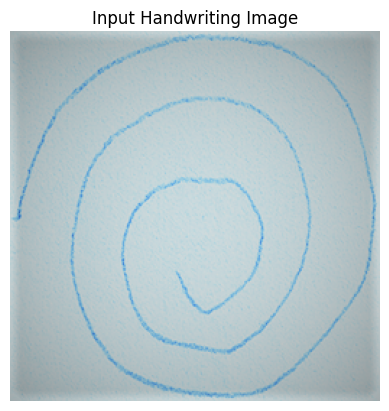

1/1 [==============================] - 3s 3s/step
Healthy probability   : 5.75%
Parkinson probability : 94.25%

Clinical Prediction: Parkinson
Confidence: 94.25%


('Parkinson', 94.25156712532043)

In [23]:
TEST_HEALTHY_DIR = "../dataset_split/test/Healthy"

img_name = random.choice(os.listdir(TEST_HEALTHY_DIR))
img_path = os.path.join(TEST_HEALTHY_DIR, img_name)

print("Testing image:", img_name)
show_image(img_path)
clinical_predict(img_path)


In [24]:
def test_multiple(folder, n=5):
    files = random.sample(os.listdir(folder), n)
    for f in files:
        print("\n==========================")
        print("Testing:", f)
        img_path = os.path.join(folder, f)
        clinical_predict(img_path)

# Example:
test_multiple("../dataset_split/test/Healthy", 5)



Testing: Healthy687.png
1/1 [==============================] - 0s 78ms/step
Healthy probability   : 5.76%
Parkinson probability : 94.24%

Clinical Prediction: Parkinson
Confidence: 94.24%

Testing: Healthy615.png
1/1 [==============================] - 0s 62ms/step
Healthy probability   : 5.83%
Parkinson probability : 94.17%

Clinical Prediction: Parkinson
Confidence: 94.17%

Testing: Healthy1404.png
1/1 [==============================] - 0s 76ms/step
Healthy probability   : 5.79%
Parkinson probability : 94.21%

Clinical Prediction: Parkinson
Confidence: 94.21%

Testing: Healthy55.png
1/1 [==============================] - 0s 71ms/step
Healthy probability   : 5.72%
Parkinson probability : 94.28%

Clinical Prediction: Parkinson
Confidence: 94.28%

Testing: Healthy365.png
1/1 [==============================] - 0s 55ms/step
Healthy probability   : 5.72%
Parkinson probability : 94.28%

Clinical Prediction: Parkinson
Confidence: 94.28%
